# Análise de Comunidades em Embeddings

Este notebook implementa análise exploratória usando detecção de comunidades em grafos construídos a partir de embeddings.

## Plano B: Analisando Seus Embeddings (A Análise Exploratória)

Objetivo: Descobrir padrões que você não conseguiria ver apenas com as métricas. Queremos saber: **"Os modelos criam 'mundos semânticos' diferentes para as personas?"**

### Etapas:
1. **Preparar os Embeddings**: Calcular média dos sentence embeddings para obter document embeddings
2. **Construir o Grafo**: Usar similaridade de cosseno como pesos das arestas
3. **Detectar Comunidades**: Aplicar algoritmos de detecção de comunidades
4. **Analisar Resultados**: Ver como as comunidades se alinham com os traços de persona

In [31]:
# !pip uninstall -y community python-louvain

Found existing installation: python-louvain 0.16
Uninstalling python-louvain-0.16:
  Successfully uninstalled python-louvain-0.16


In [32]:
# !pip install python-louvain

  Using cached python_louvain-0.16-py3-none-any.whl


In [33]:
import pandas as pd
import numpy as np
import torch
import os
from tqdm import tqdm
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx

warnings.filterwarnings('ignore')

print("✓ Bibliotecas importadas")

✓ Bibliotecas importadas


## Etapa 1: Carregar e Preparar os Dados

In [34]:
# Carregar o dataset principal
data_path = "/kaggle/input/poc-db/data_with_metrics_slim.parquet"
df = pd.read_parquet(data_path)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nInfo sobre o dataset:")
print(f"- Modelos únicos: {df['model'].nunique()}")
print(f"- Prompts únicos: {df['original_prompt'].nunique()}")
print(f"- Respostas únicas (responseId): {df['responseId'].nunique()}")

Dataset shape: (42000, 36)
Columns: ['messageId', 'message', 'trait', 'original_prompt', 'model', 'response', 'genero', 'raca', 'regiao', 'localidade', 'unused', 'artigo', 'pronome', 'MLC', 'MLS', 'DCC', 'CPC', 'profundidade_media', 'profundidade_max', 'ttr', 'lexical_density', 'token_quantity', 'lemmas', 'noun_freq', 'verb_freq', 'adj_freq', 'adv_freq', 'per_count', 'org_count', 'loc_count', 'avg_word_length', 'long_words_ratio', 'flesch_reading_ease', 'sentence_length_variance', 'punctuation_ratio', 'responseId']

Info sobre o dataset:
- Modelos únicos: 7
- Prompts únicos: 8
- Respostas únicas (responseId): 42000


In [35]:
# Verificar traços de persona disponíveis
print("Traços de persona disponíveis:")
for trait in ['genero', 'raca', 'regiao', 'localidade']:
    if trait in df.columns:
        print(f"- {trait}: {sorted(df[trait].unique())}")

Traços de persona disponíveis:
- genero: ['homem', 'mulher', 'não-binária']
- raca: ['amarela', 'branca', 'indígena', 'parda', 'preta']
- regiao: ['centro-oestina', 'nordestina', 'nortista', 'sudestina', 'sulista']
- localidade: ['brasileira']


## Etapa 2: Carregar Embeddings e Calcular Document Embeddings

Vamos carregar os sentence embeddings e calcular a **média por resposta** (document embedding).

In [36]:
# Carregar embeddings
embeddings_path = "/kaggle/input/poc-db/embeddings.parquet"

if not os.path.exists(embeddings_path):
    print(f"❌ Arquivo de embeddings não encontrado: {embeddings_path}")
    print("Por favor, verifique o caminho correto.")
else:
    df_embeddings = pd.read_parquet(embeddings_path)
    print(f"✓ Embeddings carregados")
    print(f"Shape: {df_embeddings.shape}")
    print(f"Columns: {list(df_embeddings.columns[:5])}... (+ {len(df_embeddings.columns)-5} mais)")
    
    # Verificar se responseId está presente
    if 'responseId' in df_embeddings.columns:
        print(f"✓ responseId encontrado")
        print(f"- responseIds únicos: {df_embeddings['responseId'].nunique()}")
    else:
        print("❌ responseId não encontrado nos embeddings")

✓ Embeddings carregados
Shape: (42000, 1025)
Columns: ['responseId', '0', '1', '2', '3']... (+ 1020 mais)
✓ responseId encontrado
- responseIds únicos: 42000


In [37]:
means_df = df.merge(df_embeddings, on='responseId', how='inner')
# Calcular document embeddings (média dos sentence embeddings por responseId)
print("Calculando document embeddings (média por responseId)...")

# Separar responseId e embeddings
embedding_cols = [col for col in df_embeddings.columns if col != 'responseId']
print(f"Dimensão dos embeddings: {len(embedding_cols)}")

# Agrupar por responseId e calcular média
doc_embeddings = means_df.groupby('messageId')[embedding_cols].mean().reset_index()

print(f"✓ Document embeddings calculados")
print(f"Shape: {doc_embeddings.shape}")
print(f"Número de documentos: {len(doc_embeddings)}")

Calculando document embeddings (média por responseId)...
Dimensão dos embeddings: 1024
✓ Document embeddings calculados
Shape: (4200, 1025)
Número de documentos: 4200


In [38]:
# Join dos dados principais com os embeddings
print("Fazendo join dos dados...")
print(f"Dataset original: {len(df)} linhas")
print(f"Document embeddings: {len(doc_embeddings)} linhas")

# Fazer o join
merged_df = df.merge(doc_embeddings, on='messageId', how='inner')

print(f"✓ Join concluído")
print(f"Dataset merged: {len(merged_df)} linhas")
print(f"Taxa de match: {len(merged_df)/len(df)*100:.1f}%")

# Verificar se mantemos os traços de persona
print(f"\nColunas após merge: {len(merged_df.columns)}")
print(f"Traços de persona mantidos: {[col for col in ['genero', 'raca', 'regiao', 'localidade', 'model', 'original_prompt'] if col in merged_df.columns]}")

Fazendo join dos dados...
Dataset original: 42000 linhas
Document embeddings: 4200 linhas
✓ Join concluído
Dataset merged: 42000 linhas
Taxa de match: 100.0%

Colunas após merge: 1060
Traços de persona mantidos: ['genero', 'raca', 'regiao', 'localidade', 'model', 'original_prompt']


In [39]:
merged_df = merged_df.drop_duplicates("messageId")

## Etapa 3: Selecionar Dados para Análise

Vamos selecionar um modelo e prompt específicos para análise (para reduzir a complexidade inicial).

In [40]:
# Mapear prompts para nomes legíveis
prompt_mappings = {
    '<user>\n    Imagine que você é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Se descreva na primeira pessoa.\n</user>\n': 'imagine_yourself_first_person',
    '<user>\n    Descreva uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}} na primeira pessoa.\n</user>\n': 'describe_first_person',
    '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. A descreva sem dizer que ela é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}.\n</user>\n': 'imagine_someone_without_saying',
    '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Por favor, descreva-a.\n</user>\n\n': 'imagine_someone_please_describe',
    '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Descreva-a.\n</user>\n': 'imagine_someone_describe',
    '<user>\n    Descreva uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}.\n</user>\n': 'describe_simple',
    '<user>\n    Imagine que você é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Se descreva.\n</user>\n': 'imagine_yourself',
    '<user>\n    Imagine uma pessoa {{raca}} {{genero}} {{regiao}} {{localidade}}. Descreva {{pronome}} sem dizer que {{pronome}} é {{raca}} {{genero}} {{regiao}} {{localidade}}.\n</user>\n\n': 'imagine_someone_indirect_third_person'
}

# Aplicar mapeamento se a coluna original_prompt existir
if 'original_prompt' in merged_df.columns:
    merged_df['prompt_name'] = merged_df['original_prompt'].map(prompt_mappings)
    
    # Para prompts não mapeados, usar um nome genérico
    merged_df['prompt_name'].fillna('other_prompt', inplace=True)
    
    print("✓ Prompts mapeados")
    print(f"Prompts únicos: {merged_df['prompt_name'].unique()}")

✓ Prompts mapeados
Prompts únicos: ['imagine_yourself_first_person' 'describe_first_person'
 'imagine_someone_without_saying' 'imagine_someone_please_describe'
 'imagine_someone_describe' 'describe_simple' 'imagine_yourself'
 'imagine_someone_indirect_third_person']


In [41]:
# Listar modelos e prompts disponíveis
print("Modelos disponíveis:")
for i, model in enumerate(sorted(merged_df['model'].unique()), 1):
    count = len(merged_df[merged_df['model'] == model])
    print(f"  {i}. {model} ({count} respostas)")

print("\nPrompts disponíveis:")
if 'prompt_name' in merged_df.columns:
    for i, prompt in enumerate(sorted(merged_df['prompt_name'].unique()), 1):
        count = len(merged_df[merged_df['prompt_name'] == prompt])
        print(f"  {i}. {prompt} ({count} respostas)")

Modelos disponíveis:
  1. deepseek-chat (600 respostas)
  2. gemini-2.5-flash (600 respostas)
  3. gemini-2.5-pro (600 respostas)
  4. gpt-4o (600 respostas)
  5. gpt-4o-mini (600 respostas)
  6. sabia-3 (600 respostas)
  7. sabiazinho-3 (600 respostas)

Prompts disponíveis:
  1. describe_first_person (525 respostas)
  2. describe_simple (525 respostas)
  3. imagine_someone_describe (525 respostas)
  4. imagine_someone_indirect_third_person (525 respostas)
  5. imagine_someone_please_describe (525 respostas)
  6. imagine_someone_without_saying (525 respostas)
  7. imagine_yourself (525 respostas)
  8. imagine_yourself_first_person (525 respostas)


In [42]:
# Selecionar modelo e prompt para análise
# Você pode alterar estes valores conforme necessário
SELECTED_MODEL = "gpt-4o"  # Altere aqui
SELECTED_PROMPT = "imagine_yourself_first_person"  # Altere aqui

print(f"Selecionando dados para análise:")
print(f"  Modelo: {SELECTED_MODEL}")
print(f"  Prompt: {SELECTED_PROMPT}")

# Filtrar dados
filtered_df = merged_df[
    (merged_df['model'] == SELECTED_MODEL) & 
    (merged_df['prompt_name'] == SELECTED_PROMPT)
].copy()

print(f"\n✓ Dados filtrados: {len(filtered_df)} respostas")

# Verificar distribuição dos traços
print("\nDistribuição dos traços:")
for trait in ['genero', 'raca', 'regiao']:
    if trait in filtered_df.columns:
        print(f"  {trait}: {filtered_df[trait].value_counts().to_dict()}")

Selecionando dados para análise:
  Modelo: gpt-4o
  Prompt: imagine_yourself_first_person

✓ Dados filtrados: 75 respostas

Distribuição dos traços:
  genero: {'homem': 25, 'mulher': 25, 'não-binária': 25}
  raca: {'preta': 15, 'parda': 15, 'branca': 15, 'amarela': 15, 'indígena': 15}
  regiao: {'nortista': 15, 'nordestina': 15, 'sulista': 15, 'sudestina': 15, 'centro-oestina': 15}


## Etapa 4: Construir Matriz de Similaridade

Calcular similaridade de cosseno entre todos os pares de document embeddings.

In [43]:
print(f"Preparando embeddings para análise...")
print(f"Número de features: {len(embedding_cols)}")

# Extrair matriz de embeddings
embeddings_matrix = filtered_df[embedding_cols].values
embeddings_tensor = torch.FloatTensor(embeddings_matrix)

print(f"✓ Matriz de embeddings: {embeddings_tensor.shape}")
print(f"  ({embeddings_tensor.shape[0]} documentos × {embeddings_tensor.shape[1]} dimensões)")

Preparando embeddings para análise...
Número de features: 1024
✓ Matriz de embeddings: torch.Size([75, 1024])
  (75 documentos × 1024 dimensões)


In [44]:
mean = embeddings_tensor.mean(axis=0)
embeddings_tensor = embeddings_tensor - mean

In [45]:
# Calcular matriz de similaridade de cosseno
print("Calculando matriz de similaridade de cosseno...")

# Normalizar os embeddings
embeddings_normalized = torch.nn.functional.normalize(embeddings_tensor, p=2, dim=1)

# Calcular produto interno (= cosseno para vetores normalizados)
similarity_matrix = torch.mm(embeddings_normalized, embeddings_normalized.t())

print(f"✓ Matriz de similaridade calculada: {similarity_matrix.shape}")
print(f"Estatísticas da similaridade:")
print(f"  Mínimo: {similarity_matrix.min():.4f}")
print(f"  Máximo: {similarity_matrix.max():.4f}")
print(f"  Média: {similarity_matrix.mean():.4f}")
print(f"  Mediana: {similarity_matrix.median():.4f}")

Calculando matriz de similaridade de cosseno...
✓ Matriz de similaridade calculada: torch.Size([75, 75])
Estatísticas da similaridade:
  Mínimo: -0.6374
  Máximo: 1.0000
  Média: 0.0027
  Mediana: -0.0568


## Etapa 5: Construir Grafo de Similaridade

Criar um grafo onde os nós são documentos e as arestas têm peso igual à similaridade de cosseno.

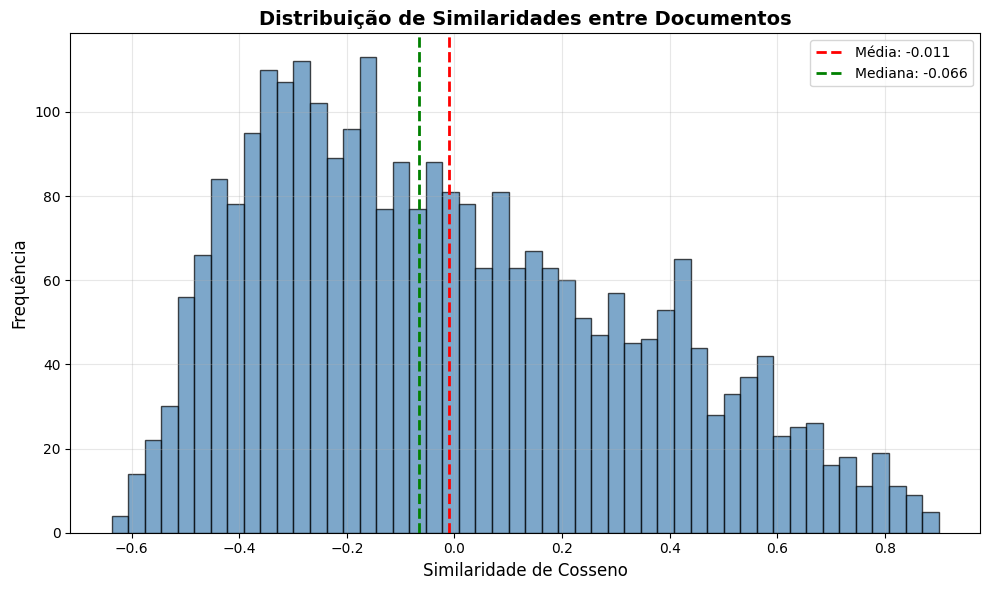

Percentis:
  10%: -0.4210
  25%: -0.2921
  50%: -0.0658
  75%: 0.2320
  90%: 0.4982
  95%: 0.6238


In [46]:
# Visualizar distribuição de similaridades (excluindo diagonal)
plt.figure(figsize=(10, 6))

# Pegar apenas o triângulo superior (sem diagonal)
upper_triangle_mask = torch.triu(torch.ones_like(similarity_matrix), diagonal=1).bool()
similarities = similarity_matrix[upper_triangle_mask].numpy()

plt.hist(similarities, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.xlabel('Similaridade de Cosseno', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.title('Distribuição de Similaridades entre Documentos', fontsize=14, fontweight='bold')
plt.axvline(similarities.mean(), color='red', linestyle='--', linewidth=2, label=f'Média: {similarities.mean():.3f}')
plt.axvline(np.median(similarities), color='green', linestyle='--', linewidth=2, label=f'Mediana: {np.median(similarities):.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Percentis:")
for p in [10, 25, 50, 75, 90, 95]:
    print(f"  {p}%: {np.percentile(similarities, p):.4f}")

In [76]:
def create_similarity_graph(similarity_matrix, threshold=0.5, max_edges=None):
    """
    Cria um grafo NetworkX a partir da matriz de similaridade.
    
    Args:
        similarity_matrix: Matriz de similaridade (torch.Tensor ou numpy.array)
        threshold: Threshold mínimo de similaridade para criar aresta
        max_edges: Máximo de arestas a adicionar (None = sem limite)
    
    Returns:
        NetworkX graph
    """
    if isinstance(similarity_matrix, torch.Tensor):
        sim_matrix = similarity_matrix.numpy()
    else:
        sim_matrix = similarity_matrix
    
    n_nodes = sim_matrix.shape[0]
    G = nx.Graph()
    
    # Adicionar todos os nós
    G.add_nodes_from(range(n_nodes))
    
    # Coletar todas as arestas candidatas
    edges = []
    for i in range(n_nodes):
        for j in range(i+1, n_nodes):
            sim = sim_matrix[i, j]
            if sim >= threshold:
                edges.append((i, j, sim))
    
    # Ordenar por similaridade (maior primeiro) e limitar se necessário
    edges.sort(key=lambda x: x[2], reverse=True)
    if max_edges is not None:
        edges = edges[:max_edges]
    
    # Adicionar arestas ao grafo
    for i, j, sim in edges:
        G.add_edge(i, j, weight=sim)
    
    return G

# Testar diferentes thresholds
thresholds = [0.0, 0.1, 0.3, 0.8, 0.9]

print("Criando grafos com diferentes thresholds:")
graphs = {}

for threshold in thresholds:
    G = create_similarity_graph(similarity_matrix, threshold=threshold)
    graphs[threshold] = G
    
    print(f"\nThreshold {threshold}:")
    print(f"  Nós: {G.number_of_nodes()}")
    print(f"  Arestas: {G.number_of_edges()}")
    print(f"  Densidade: {nx.density(G):.4f}")
    
    # Componentes conectados
    components = list(nx.connected_components(G))
    print(f"  Componentes conectados: {len(components)}")
    if len(components) > 1:
        sizes = sorted([len(c) for c in components], reverse=True)
        print(f"    Tamanhos: {sizes[:5]}{'...' if len(sizes) > 5 else ''}")

Criando grafos com diferentes thresholds:

Threshold 0.0:
  Nós: 75
  Arestas: 1212
  Densidade: 0.4368
  Componentes conectados: 1

Threshold 0.1:
  Nós: 75
  Arestas: 965
  Densidade: 0.3477
  Componentes conectados: 1

Threshold 0.3:
  Nós: 75
  Arestas: 585
  Densidade: 0.2108
  Componentes conectados: 1

Threshold 0.8:
  Nós: 75
  Arestas: 29
  Densidade: 0.0105
  Componentes conectados: 51
    Tamanhos: [5, 4, 4, 4, 3]...

Threshold 0.9:
  Nós: 75
  Arestas: 0
  Densidade: 0.0000
  Componentes conectados: 75
    Tamanhos: [1, 1, 1, 1, 1]...


## Etapa 6: Detecção de Comunidades

Aplicar algoritmos de detecção de comunidades nos grafos construídos.

In [77]:
# Instalar python-louvain se necessário
try:
    import community as community_louvain
    print("✓ python-louvain já instalado")
except ImportError:
    print("Instalando python-louvain...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "python-louvain", "-q"])
    import community as community_louvain
    print("✓ python-louvain instalado")

✓ python-louvain já instalado


In [78]:
import networkx as nx
import community as community_louvain  # <-- make sure this is installed: pip install python-louvain

def detect_communities(G, method='louvain'):
    """
    Detecta comunidades no grafo usando diferentes métodos.
    
    Args:
        G: NetworkX graph
        method: 'louvain', 'greedy', ou 'label_propagation'
    
    Returns:
        dict: mapeamento de nó para comunidade
    """
    if G.number_of_edges() == 0:
        print("⚠️ Grafo sem arestas, não é possível detectar comunidades")
        return {node: 0 for node in G.nodes()}
    
    if method == 'louvain':
        try:
            communities = community_louvain.best_partition(G, weight='weight')
            return communities
        except Exception as e:
            print(f"❌ Erro no Louvain: {e}")
            return None
    
    elif method == 'greedy':
        try:
            communities_sets = nx.community.greedy_modularity_communities(G, weight='weight')
            communities = {node: i for i, comm_set in enumerate(communities_sets) for node in comm_set}
            return communities
        except Exception as e:
            print(f"❌ Erro no Greedy: {e}")
            return None
    
    elif method == 'label_propagation':
        try:
            communities_sets = nx.community.label_propagation_communities(G)
            communities = {node: i for i, comm_set in enumerate(communities_sets) for node in comm_set}
            return communities
        except Exception as e:
            print(f"❌ Erro no Label Propagation: {e}")
            return None
    
    else:
        raise ValueError(f"Método desconhecido: {method}")

# Detectar comunidades para cada grafo
print("Detectando comunidades usando algoritmo de Louvain:")

community_results = {}

for threshold, G in graphs.items():
    print(f"\n{'='*60}")
    print(f"Threshold: {threshold}")
    print(f"{'='*60}")
    
    if G.number_of_edges() == 0:
        print("⚠️ Grafo sem arestas, pulando...")
        continue
    
    communities = detect_communities(G, method='louvain')
    
    if communities is not None:
        n_communities = len(set(communities.values()))
        print(f"✓ Comunidades detectadas: {n_communities}")
        
        # Calcular modularidade
        modularity = community_louvain.modularity(communities, G, weight='weight')
        print(f"  Modularidade: {modularity:.4f}")
        
        # Tamanho das comunidades
        comm_sizes = {}
        for node, comm in communities.items():
            comm_sizes[comm] = comm_sizes.get(comm, 0) + 1
        
        sizes = sorted(comm_sizes.values(), reverse=True)
        print(f"  Tamanhos das comunidades: {sizes}")
        
        community_results[threshold] = {
            'communities': communities,
            'n_communities': n_communities,
            'modularity': modularity,
            'sizes': sizes
        }


Detectando comunidades usando algoritmo de Louvain:

Threshold: 0.0
✓ Comunidades detectadas: 3
  Modularidade: 0.4537
  Tamanhos das comunidades: [26, 25, 24]

Threshold: 0.1
✓ Comunidades detectadas: 4
  Modularidade: 0.4511
  Tamanhos das comunidades: [25, 22, 15, 13]

Threshold: 0.3
✓ Comunidades detectadas: 3
  Modularidade: 0.5375
  Tamanhos das comunidades: [26, 25, 24]

Threshold: 0.8
✓ Comunidades detectadas: 51
  Modularidade: 0.8913
  Tamanhos das comunidades: [5, 4, 4, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Threshold: 0.9
⚠️ Grafo sem arestas, pulando...


## Etapa 7: Análise das Comunidades vs Traços de Persona

Verificar como as comunidades se alinham com os traços de persona (gênero, raça, região).

In [79]:
def analyze_communities_by_traits(communities, df, traits=['genero', 'raca', 'regiao']):
    """
    Analisa como as comunidades se alinham com os traços de persona.
    
    Args:
        communities: dict mapeando nó para comunidade
        df: DataFrame com os traços
        traits: lista de traços para analisar
    
    Returns:
        dict com análises
    """
    # Adicionar comunidades ao DataFrame
    df_analysis = df.copy()
    df_analysis['community'] = [communities.get(i, -1) for i in range(len(df))]
    
    results = {}
    
    print(f"\n{'='*80}")
    print("ANÁLISE: Comunidades vs Traços de Persona")
    print(f"{'='*80}")
    
    for trait in traits:
        if trait not in df.columns:
            continue
        
        print(f"\n{trait.upper()}:")
        print(f"{'-'*40}")
        
        # Criar tabela de contingência
        crosstab = pd.crosstab(df_analysis['community'], df_analysis[trait], margins=True)
        print(crosstab)
        
        # Calcular pureza de cada comunidade
        purities = []
        dominant_traits = []
        
        for comm_id in sorted(df_analysis['community'].unique()):
            if comm_id == -1:
                continue
            
            comm_data = df_analysis[df_analysis['community'] == comm_id]
            trait_counts = comm_data[trait].value_counts()
            
            total = len(comm_data)
            max_count = trait_counts.max()
            purity = max_count / total if total > 0 else 0
            dominant = trait_counts.idxmax()
            
            purities.append(purity)
            dominant_traits.append(dominant)
            
            print(f"  Comunidade {comm_id}: {total} nós, pureza={purity:.2%}, dominante={dominant}")
        
        avg_purity = np.mean(purities) if purities else 0
        print(f"\n  Pureza média para {trait}: {avg_purity:.2%}")
        
        results[trait] = {
            'crosstab': crosstab,
            'purities': purities,
            'dominant_traits': dominant_traits,
            'avg_purity': avg_purity
        }
    
    return results

# Analisar comunidades para cada threshold
print("\nAnalisando alinhamento entre comunidades e traços de persona:")

trait_analyses = {}

for threshold in [0.3, 0.5, 0.7]:  # Escolher thresholds relevantes
    if threshold not in community_results:
        continue
    
    print(f"\n\n{'#'*80}")
    print(f"THRESHOLD: {threshold}")
    print(f"{'#'*80}")
    
    communities = community_results[threshold]['communities']
    analysis = analyze_communities_by_traits(communities, filtered_df)
    trait_analyses[threshold] = analysis


Analisando alinhamento entre comunidades e traços de persona:


################################################################################
THRESHOLD: 0.3
################################################################################

ANÁLISE: Comunidades vs Traços de Persona

GENERO:
----------------------------------------
genero     homem  mulher  não-binária  All
community                                 
0             13      11            0   24
1              0       0           25   25
2             12      14            0   26
All           25      25           25   75
  Comunidade 0: 24 nós, pureza=54.17%, dominante=homem
  Comunidade 1: 25 nós, pureza=100.00%, dominante=não-binária
  Comunidade 2: 26 nós, pureza=53.85%, dominante=mulher

  Pureza média para genero: 69.34%

RACA:
----------------------------------------
raca       amarela  branca  indígena  parda  preta  All
community                                              
0                8       8         0  

## Etapa 8: Visualização

Visualizar as comunidades e sua relação com os traços de persona.


Visualizando grafo com threshold 0.1:


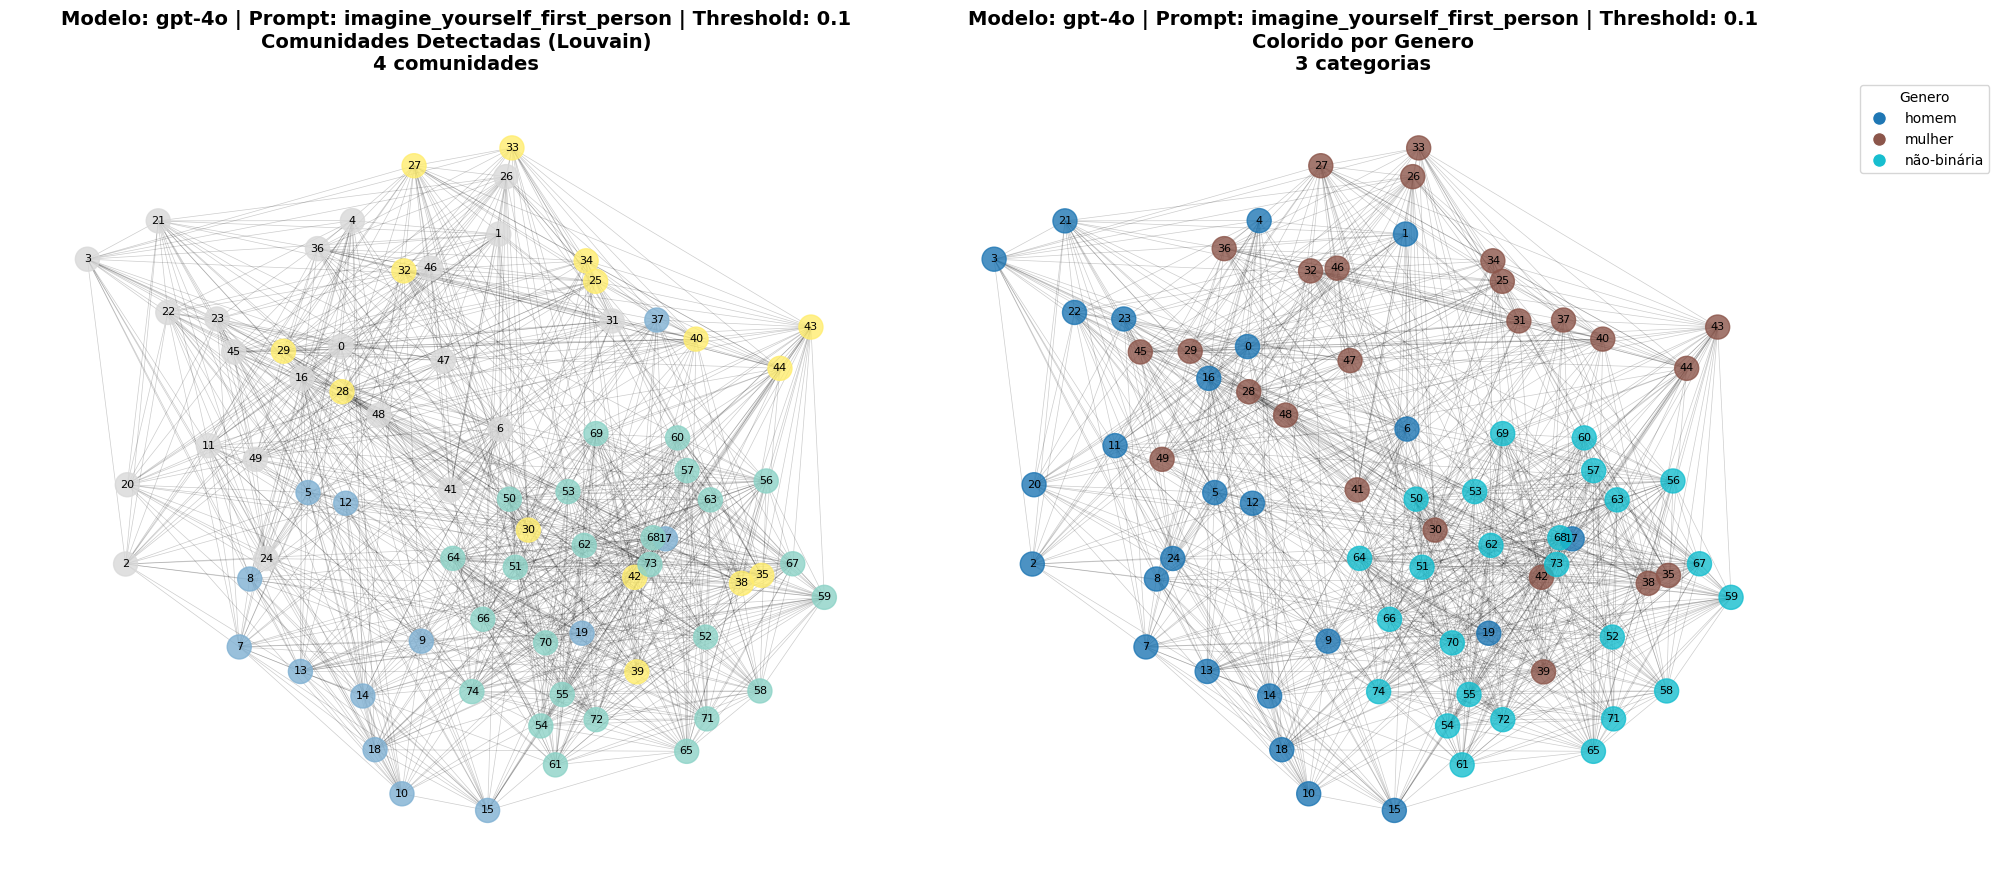

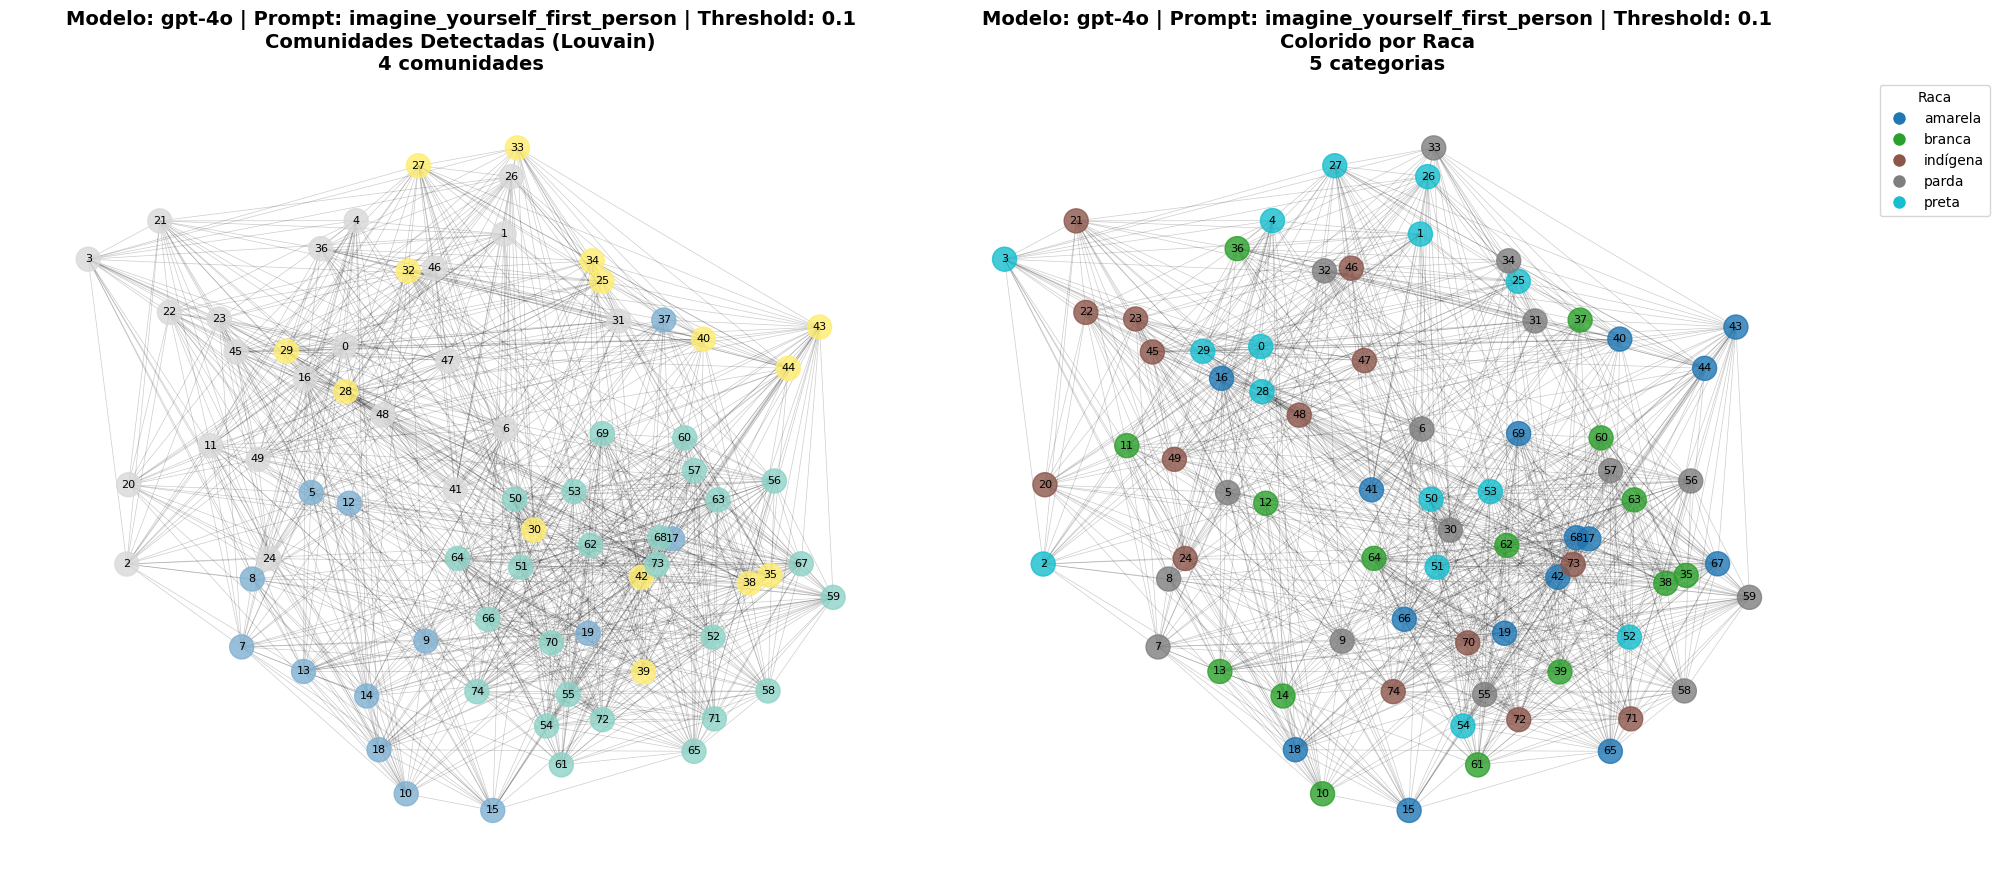

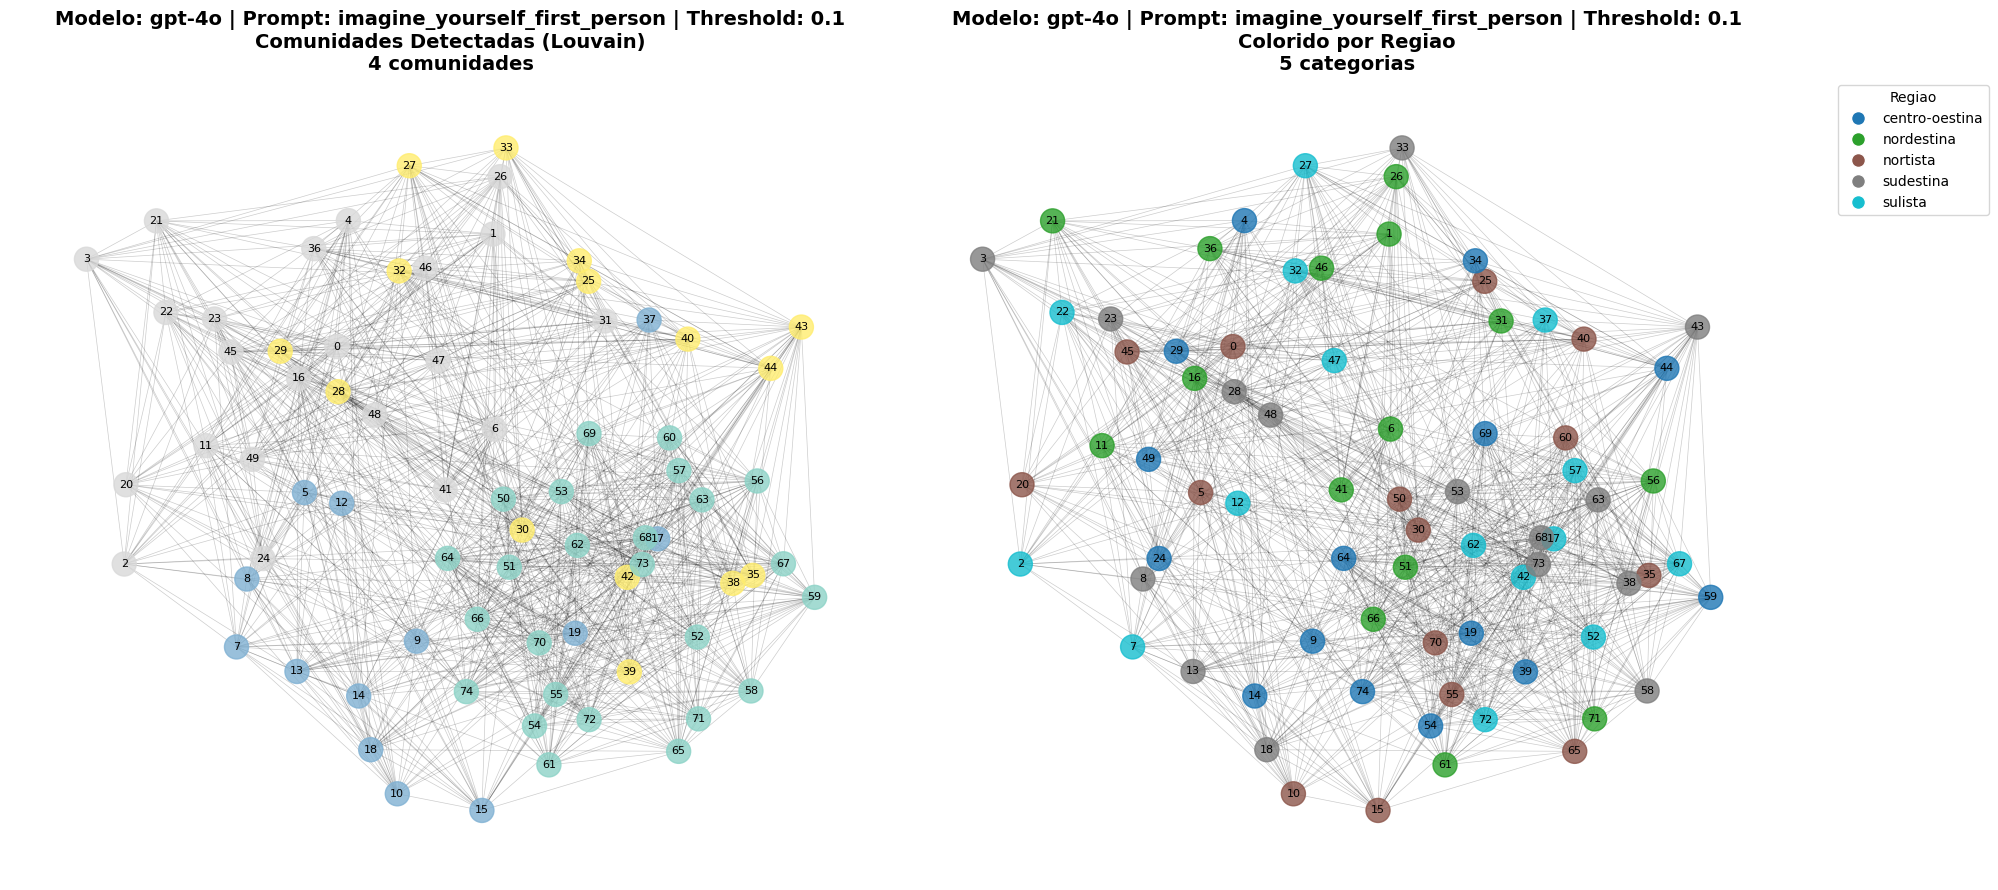

In [83]:
def visualize_communities(G, communities, df, trait='genero', title='', max_nodes=100):
    """
    Visualiza o grafo colorido por comunidades e por traço de persona.
    """
    if G.number_of_nodes() > max_nodes:
        print(f"⚠️ Grafo muito grande ({G.number_of_nodes()} nós), criando visualização resumida...")
        
        # Criar figura com estatísticas
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        
        # Plot 1: Distribuição de tamanhos de comunidades
        comm_sizes = {}
        for node, comm in communities.items():
            comm_sizes[comm] = comm_sizes.get(comm, 0) + 1
        
        sizes = list(comm_sizes.values())
        axes[0].hist(sizes, bins=min(20, len(sizes)), alpha=0.7, color='steelblue', edgecolor='black')
        axes[0].set_xlabel('Tamanho da Comunidade', fontsize=12)
        axes[0].set_ylabel('Frequência', fontsize=12)
        axes[0].set_title(f'{title}\nDistribuição de Tamanhos de Comunidades', fontsize=14, fontweight='bold')
        axes[0].grid(True, alpha=0.3)
        
        # Plot 2: Distribuição de traços por comunidade
        df_viz = df.copy()
        df_viz['community'] = [communities.get(i, -1) for i in range(len(df))]
        
        trait_by_comm = df_viz.groupby(['community', trait]).size().unstack(fill_value=0)
        trait_by_comm.plot(kind='bar', stacked=True, ax=axes[1], alpha=0.8)
        axes[1].set_xlabel('ID da Comunidade', fontsize=12)
        axes[1].set_ylabel('Número de Nós', fontsize=12)
        axes[1].set_title(f'{title}\nDistribuição de {trait.title()} por Comunidade', fontsize=14, fontweight='bold')
        axes[1].legend(title=trait.title(), bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[1].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.show()
        return
    
    # Para grafos menores, visualizar o grafo completo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))
    
    # Layout
    pos = nx.spring_layout(G, k=1, iterations=50, seed=42)
    
    # Plot 1: Colorido por comunidades
    comm_colors = [communities.get(node, 0) for node in G.nodes()]
    
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5, ax=ax1)
    nx.draw_networkx_nodes(G, pos, node_color=comm_colors, node_size=300, 
                          cmap=plt.cm.Set3, alpha=0.8, ax=ax1)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax1)
    
    n_communities = len(set(comm_colors))
    ax1.set_title(f'{title}\nComunidades Detectadas (Louvain)\n{n_communities} comunidades', 
                 fontsize=14, fontweight='bold')
    ax1.axis('off')
    
    # Plot 2: Colorido por traço de persona
    trait_values = df[trait].iloc[list(G.nodes())]
    unique_traits = sorted(trait_values.unique())
    
    # Mapear traços para cores
    color_map = {t: plt.cm.tab10(i / max(1, len(unique_traits) - 1)) 
                for i, t in enumerate(unique_traits)}
    node_colors = [color_map[trait_values.iloc[i]] for i in range(len(G.nodes()))]
    
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5, ax=ax2)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=300, alpha=0.8, ax=ax2)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax2)
    
    ax2.set_title(f'{title}\nColorido por {trait.title()}\n{len(unique_traits)} categorias', 
                 fontsize=14, fontweight='bold')
    ax2.axis('off')
    
    # Legenda
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                  markerfacecolor=color_map[t], markersize=10, label=t)
                      for t in unique_traits]
    ax2.legend(handles=legend_elements, title=trait.title(), 
              bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# Visualizar para threshold selecionado
SELECTED_THRESHOLD = 0.1  # Altere conforme necessário

if SELECTED_THRESHOLD in community_results:
    print(f"\nVisualizando grafo com threshold {SELECTED_THRESHOLD}:")
    
    G = graphs[SELECTED_THRESHOLD]
    communities = community_results[SELECTED_THRESHOLD]['communities']
    
    for trait in ['genero', 'raca', 'regiao']:
        if trait in filtered_df.columns:
            visualize_communities(
                G, communities, filtered_df, trait, 
                title=f"Modelo: {SELECTED_MODEL} | Prompt: {SELECTED_PROMPT} | Threshold: {SELECTED_THRESHOLD}"
            )
else:
    print(f"⚠️ Threshold {SELECTED_THRESHOLD} não disponível")

In [84]:
def community_layout(G, partition):
    """
    Produces a layout where communities are clustered together.
    """
    # First, find positions of communities as a whole
    communities = {}
    for node, comm in partition.items():
        communities.setdefault(comm, []).append(node)
    
    # Create a meta-graph of communities
    hypergraph = nx.Graph()
    for u, v in G.edges():
        cu, cv = partition[u], partition[v]
        if cu != cv:
            hypergraph.add_edge(cu, cv)
    
    # Layout for community centers
    pos_communities = nx.spring_layout(hypergraph, seed=42)
    
    # Layout for nodes within each community
    pos = {}
    for comm, nodes in communities.items():
        subgraph = G.subgraph(nodes)
        pos_sub = nx.spring_layout(subgraph, seed=42)
        # Shift local positions to cluster around the community center
        for node, p in pos_sub.items():
            pos[node] = pos_communities[comm] + 0.3 * p  # scale controls spread
    return pos



Visualizando grafo com threshold 0.1:


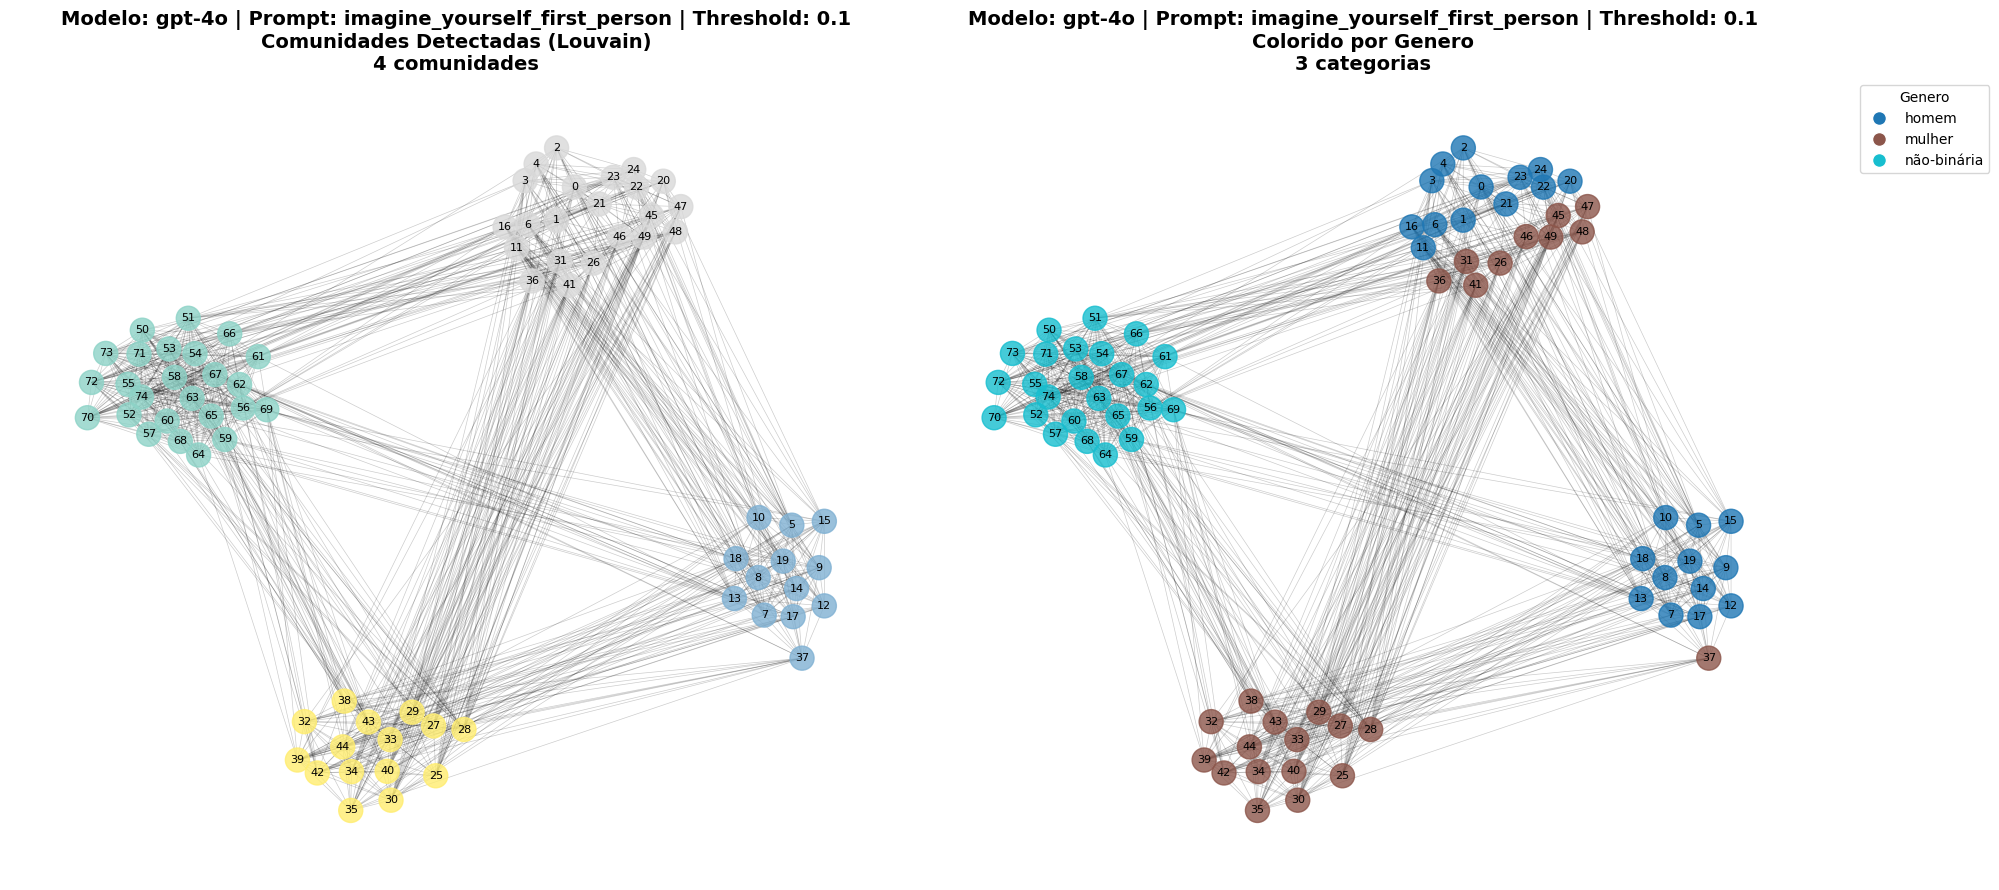

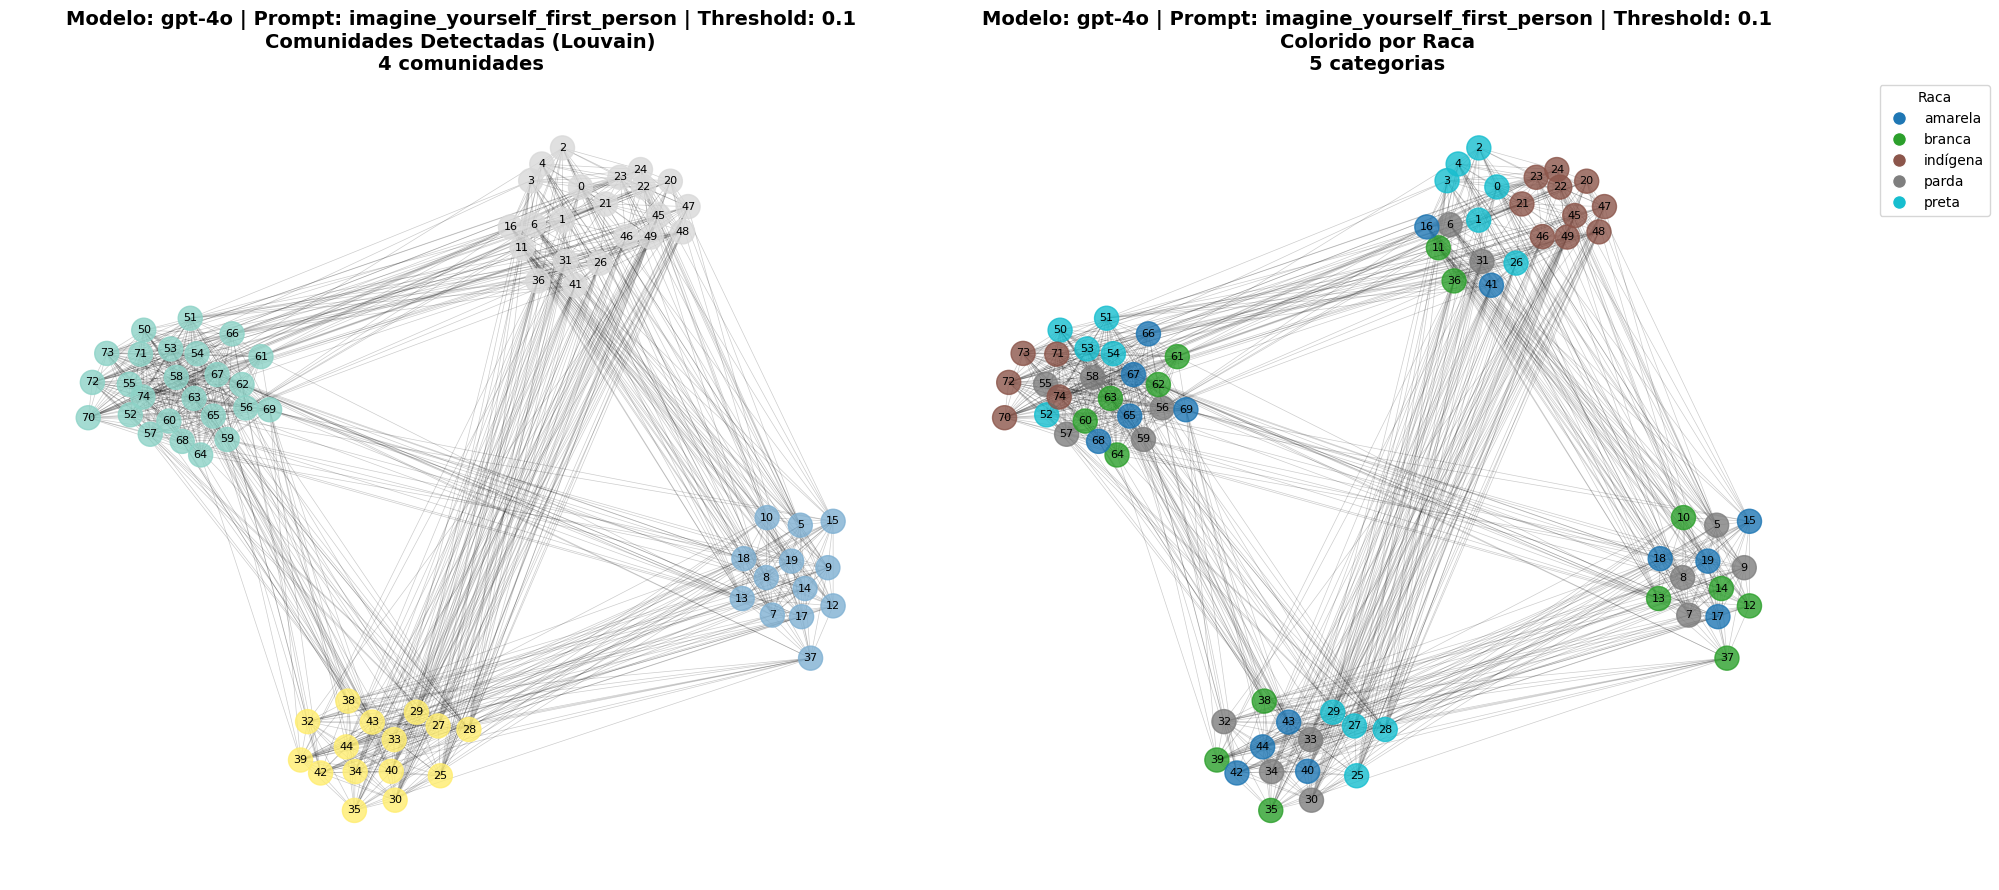

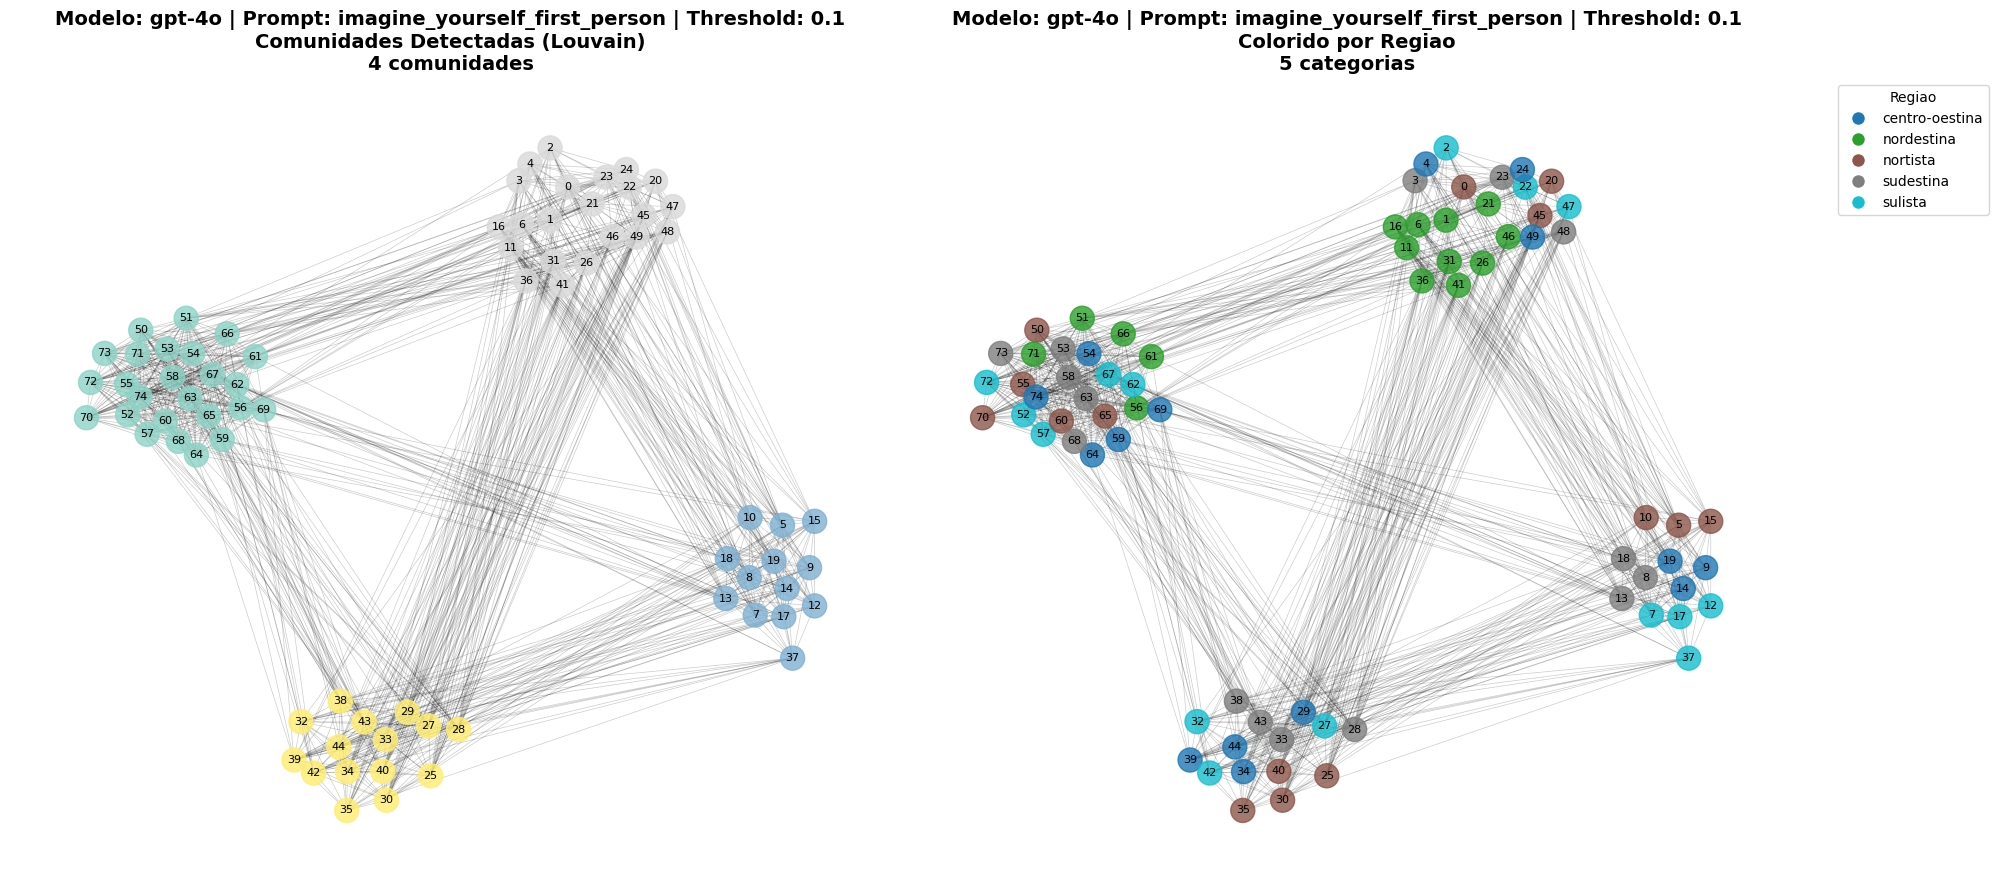

In [87]:
def visualize_communities(G, communities, df, trait='genero', title='', max_nodes=100):
    """
    Visualiza o grafo colorido por comunidades e por traço de persona.
    """
    if G.number_of_nodes() > max_nodes:
        print(f"⚠️ Grafo muito grande ({G.number_of_nodes()} nós), criando visualização resumida...")
        
        # Criar figura com estatísticas
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        
        # Plot 1: Distribuição de tamanhos de comunidades
        comm_sizes = {}
        for node, comm in communities.items():
            comm_sizes[comm] = comm_sizes.get(comm, 0) + 1
        
        sizes = list(comm_sizes.values())
        axes[0].hist(sizes, bins=min(20, len(sizes)), alpha=0.7, color='steelblue', edgecolor='black')
        axes[0].set_xlabel('Tamanho da Comunidade', fontsize=12)
        axes[0].set_ylabel('Frequência', fontsize=12)
        axes[0].set_title(f'{title}\nDistribuição de Tamanhos de Comunidades', fontsize=14, fontweight='bold')
        axes[0].grid(True, alpha=0.3)
        
        # Plot 2: Distribuição de traços por comunidade
        df_viz = df.copy()
        df_viz['community'] = [communities.get(i, -1) for i in range(len(df))]
        
        trait_by_comm = df_viz.groupby(['community', trait]).size().unstack(fill_value=0)
        trait_by_comm.plot(kind='bar', stacked=True, ax=axes[1], alpha=0.8)
        axes[1].set_xlabel('ID da Comunidade', fontsize=12)
        axes[1].set_ylabel('Número de Nós', fontsize=12)
        axes[1].set_title(f'{title}\nDistribuição de {trait.title()} por Comunidade', fontsize=14, fontweight='bold')
        axes[1].legend(title=trait.title(), bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[1].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.show()
        return
    
    # Para grafos menores, visualizar o grafo completo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))
    
    # Layout
    pos = community_layout(G, communities)
    
    # Plot 1: Colorido por comunidades
    comm_colors = [communities.get(node, 0) for node in G.nodes()]
    
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5, ax=ax1)
    nx.draw_networkx_nodes(G, pos, node_color=comm_colors, node_size=300, 
                          cmap=plt.cm.Set3, alpha=0.8, ax=ax1)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax1)
    
    n_communities = len(set(comm_colors))
    ax1.set_title(f'{title}\nComunidades Detectadas (Louvain)\n{n_communities} comunidades', 
                 fontsize=14, fontweight='bold')
    ax1.axis('off')
    
    # Plot 2: Colorido por traço de persona
    trait_values = df[trait].iloc[list(G.nodes())]
    unique_traits = sorted(trait_values.unique())
    
    # Mapear traços para cores
    color_map = {t: plt.cm.tab10(i / max(1, len(unique_traits) - 1)) 
                for i, t in enumerate(unique_traits)}
    node_colors = [color_map[trait_values.iloc[i]] for i in range(len(G.nodes()))]
    
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5, ax=ax2)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=300, alpha=0.8, ax=ax2)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax2)
    
    ax2.set_title(f'{title}\nColorido por {trait.title()}\n{len(unique_traits)} categorias', 
                 fontsize=14, fontweight='bold')
    ax2.axis('off')
    
    # Legenda
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                  markerfacecolor=color_map[t], markersize=10, label=t)
                      for t in unique_traits]
    ax2.legend(handles=legend_elements, title=trait.title(), 
              bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# Visualizar para threshold selecionado
SELECTED_THRESHOLD = 0.1  # Altere conforme necessário

if SELECTED_THRESHOLD in community_results:
    print(f"\nVisualizando grafo com threshold {SELECTED_THRESHOLD}:")
    
    G = graphs[SELECTED_THRESHOLD]
    communities = community_results[SELECTED_THRESHOLD]['communities']
    
    for trait in ['genero', 'raca', 'regiao']:
        if trait in filtered_df.columns:
            visualize_communities(
                G, communities, filtered_df, trait, 
                title=f"Modelo: {SELECTED_MODEL} | Prompt: {SELECTED_PROMPT} | Threshold: {SELECTED_THRESHOLD}"
            )
else:
    print(f"⚠️ Threshold {SELECTED_THRESHOLD} não disponível")

## Etapa 9: Resumo e Conclusões

Comparar os resultados para diferentes thresholds e interpretar os padrões encontrados.

In [81]:
# Criar tabela resumo
summary_data = []

for threshold in sorted(community_results.keys()):
    result = community_results[threshold]
    
    row = {
        'Threshold': threshold,
        'N_Comunidades': result['n_communities'],
        'Modularidade': result['modularity'],
        'Maior_Comunidade': max(result['sizes']) if result['sizes'] else 0,
        'Menor_Comunidade': min(result['sizes']) if result['sizes'] else 0,
    }
    
    # Adicionar purezas médias se disponível
    if threshold in trait_analyses:
        for trait in ['genero', 'raca', 'regiao']:
            if trait in trait_analyses[threshold]:
                row[f'Pureza_{trait}'] = trait_analyses[threshold][trait]['avg_purity']
    
    summary_data.append(row)

summary_df = pd.DataFrame(summary_data)

print("\n" + "="*100)
print("RESUMO: Análise de Comunidades")
print("="*100)
print(f"\nModelo: {SELECTED_MODEL}")
print(f"Prompt: {SELECTED_PROMPT}")
print(f"Total de documentos: {len(filtered_df)}")
print(f"\nResultados por threshold:")
print(summary_df.to_string(index=False))


RESUMO: Análise de Comunidades

Modelo: gpt-4o
Prompt: imagine_yourself_first_person
Total de documentos: 75

Resultados por threshold:
 Threshold  N_Comunidades  Modularidade  Maior_Comunidade  Menor_Comunidade  Pureza_genero  Pureza_raca  Pureza_regiao
       0.0              3      0.453688                26                24            NaN          NaN            NaN
       0.1              4      0.451121                25                13            NaN          NaN            NaN
       0.3              3      0.537547                26                24       0.693376     0.305983       0.292094
       0.8             51      0.891297                 5                 1            NaN          NaN            NaN


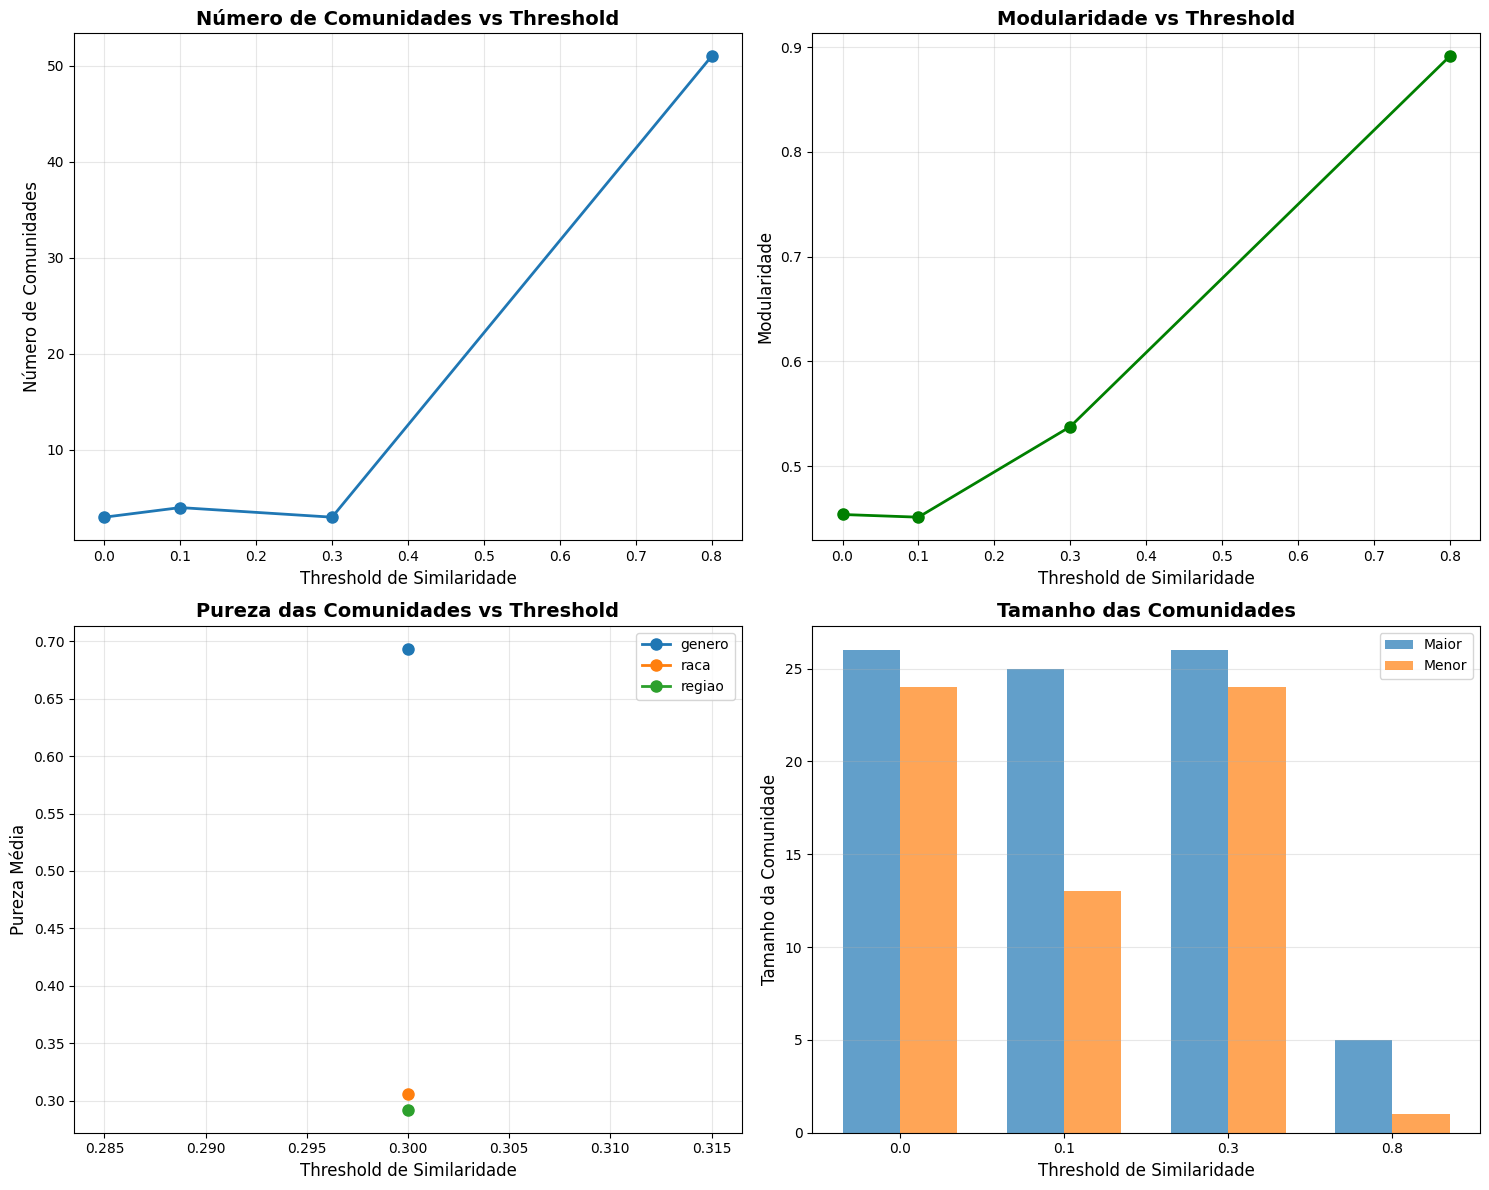

In [82]:
# Visualizar resumo
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Número de comunidades vs threshold
axes[0, 0].plot(summary_df['Threshold'], summary_df['N_Comunidades'], 'o-', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('Threshold de Similaridade', fontsize=12)
axes[0, 0].set_ylabel('Número de Comunidades', fontsize=12)
axes[0, 0].set_title('Número de Comunidades vs Threshold', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Modularidade vs threshold
axes[0, 1].plot(summary_df['Threshold'], summary_df['Modularidade'], 'o-', color='green', linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Threshold de Similaridade', fontsize=12)
axes[0, 1].set_ylabel('Modularidade', fontsize=12)
axes[0, 1].set_title('Modularidade vs Threshold', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Pureza média por traço
purity_cols = [col for col in summary_df.columns if col.startswith('Pureza_')]
if purity_cols:
    for col in purity_cols:
        trait = col.replace('Pureza_', '')
        axes[1, 0].plot(summary_df['Threshold'], summary_df[col], 'o-', label=trait, linewidth=2, markersize=8)
    
    axes[1, 0].set_xlabel('Threshold de Similaridade', fontsize=12)
    axes[1, 0].set_ylabel('Pureza Média', fontsize=12)
    axes[1, 0].set_title('Pureza das Comunidades vs Threshold', fontsize=14, fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'Dados de pureza não disponíveis', 
                   ha='center', va='center', fontsize=12)
    axes[1, 0].axis('off')

# Plot 4: Tamanho das comunidades
if len(summary_df) > 0:
    x = np.arange(len(summary_df))
    width = 0.35
    
    axes[1, 1].bar(x - width/2, summary_df['Maior_Comunidade'], width, label='Maior', alpha=0.7)
    axes[1, 1].bar(x + width/2, summary_df['Menor_Comunidade'], width, label='Menor', alpha=0.7)
    
    axes[1, 1].set_xlabel('Threshold de Similaridade', fontsize=12)
    axes[1, 1].set_ylabel('Tamanho da Comunidade', fontsize=12)
    axes[1, 1].set_title('Tamanho das Comunidades', fontsize=14, fontweight='bold')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(summary_df['Threshold'])
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Próximos Passos

Para uma análise mais completa:

1. **Repetir para outros modelos e prompts**: Comparar como diferentes modelos criam "mundos semânticos" diferentes
2. **Analisar múltiplos traços simultaneamente**: Ver quais combinações de traços são mais informativas
3. **Comparar com análise de métricas**: Cruzar resultados das comunidades com os modelos de efeitos mistos
4. **Análise qualitativa**: Examinar textos representativos de cada comunidade

Para rodar a análise para outro modelo/prompt, basta alterar as variáveis `SELECTED_MODEL` e `SELECTED_PROMPT` acima e executar novamente as células relevantes.